In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
DATA_PATH = "/Users/christinandayisenga/Downloads/pd_speech_features.csv"

df = pd.read_csv(DATA_PATH, header=1)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


Part 1: Understanding the data

Prediction task:

The goal is to use voice recordings to predict whether a person has Parkinson’s disease (class 1) or is healthy (class 0). This model could help healthcare professionals or researchers see if voice features can be useful for screening. Since the dataset has more recordings from people with Parkinson’s than healthy people, I will look at ROC AUC, sensitivity, specificity, and average precision instead of relying only on accuracy.

In [19]:
SUBJECT_COL = subject_candidates[0]
TARGET_COL = target_candidates[0]

print("Subject column:", SUBJECT_COL)
print("Target column:", TARGET_COL)
print("\nTarget values and counts:")
print(df[TARGET_COL].value_counts(dropna=False))
print("\nMissing values in target:", df[TARGET_COL].isna().sum())
print("Missing values in subject ID:", df[SUBJECT_COL].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("\nRecordings per subject (value counts):")
print(df.groupby(SUBJECT_COL).size().value_counts().sort_index())
print("Number of unique subjects:", df[SUBJECT_COL].nunique())

Subject column: id
Target column: class

Target values and counts:
class
1    564
0    192
Name: count, dtype: int64

Missing values in target: 0
Missing values in subject ID: 0
Exact duplicate rows: 1

Recordings per subject (value counts):
3    252
Name: count, dtype: int64
Number of unique subjects: 252


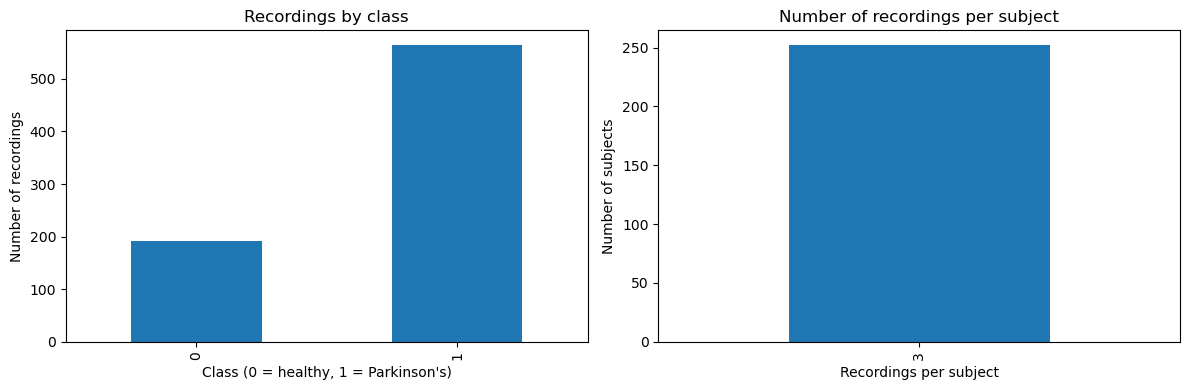

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Recordings by class")
axes[0].set_xlabel("Class (0 = healthy, 1 = Parkinson's)")
axes[0].set_ylabel("Number of recordings")
df.groupby(SUBJECT_COL).size().value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Number of recordings per subject")
axes[1].set_xlabel("Recordings per subject")
axes[1].set_ylabel("Number of subjects")
plt.tight_layout()
plt.show()

In [23]:
class_counts = df[TARGET_COL].value_counts().sort_index()
class_props = df[TARGET_COL].value_counts(normalize=True).sort_index()
print("Class counts:")
print(class_counts)
print("\nClass proportions:")
print(class_props.round(3))

majority_class = class_counts.idxmax()
majority_accuracy = class_counts.max() / len(df)
print(f"Majority class: {majority_class}")
print(f"Always-predict-majority accuracy: {majority_accuracy:.3f}")

Class counts:
class
0    192
1    564
Name: count, dtype: int64

Class proportions:
class
0    0.254
1    0.746
Name: proportion, dtype: float64
Majority class: 1
Always-predict-majority accuracy: 0.746


In [22]:
print("Rows with any missing values:", df.isna().any(axis=1).sum())
print("Columns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Rows with any missing values: 0
Columns with missing values:
Series([], dtype: int64)


Q1. 

Each observation is one sustained-vowel voice recording. However, each person has multiple recordings, so the recordings from the same person are related. Because of this, I will split the data and perform cross-validation using subject ID to make sure the same person does not appear in both the training and validation or test sets.

Q2.

The majority-class accuracy is shown in the results above. Accuracy by itself may not tell the full story because the dataset has more recordings from one class than the other. I will also use ROC AUC, sensitivity/recall, specificity, and average precision to get a better idea of how well the model performs. The graphs show the class distribution and how many recordings each person has, which helps explain why I need to split the data by subject instead of randomly splitting individual recordings.

PART 2: SPLITING AND LEAKAGE

In [27]:
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedGroupKFold,
    GroupKFold, GridSearchCV, RandomizedSearchCV, learning_curve
)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [32]:
subject_label_counts = df.groupby(SUBJECT_COL)[TARGET_COL].nunique()

subject_table = df[[SUBJECT_COL, TARGET_COL]].drop_duplicates(SUBJECT_COL).copy()
train_subjects, test_subjects = train_test_split(
    subject_table[SUBJECT_COL],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=subject_table[TARGET_COL]
)

train_df = df[df[SUBJECT_COL].isin(train_subjects)].copy().reset_index(drop=True)
test_df = df[df[SUBJECT_COL].isin(test_subjects)].copy().reset_index(drop=True)

print("Training rows:", len(train_df), "| Test rows:", len(test_df))
print("Training subjects:", train_df[SUBJECT_COL].nunique(),
      "| Test subjects:", test_df[SUBJECT_COL].nunique())
overlap = set(train_df[SUBJECT_COL]) & set(test_df[SUBJECT_COL])
print("Subject overlap:", len(overlap))
assert len(overlap) == 0
print("Training class counts:")
print(train_df[TARGET_COL].value_counts().sort_index())
print("Test class counts:")
print(test_df[TARGET_COL].value_counts().sort_index())

Training rows: 603 | Test rows: 153
Training subjects: 201 | Test subjects: 51
Subject overlap: 0
Training class counts:
class
0    153
1    450
Name: count, dtype: int64
Test class counts:
class
0     39
1    114
Name: count, dtype: int64


In [33]:
FEATURE_COLS = [c for c in df.columns if c not in [SUBJECT_COL, TARGET_COL]]
X_train = train_df[FEATURE_COLS].apply(pd.to_numeric, errors="coerce")
y_train = train_df[TARGET_COL].astype(int)
groups_train = train_df[SUBJECT_COL].to_numpy()

X_test = test_df[FEATURE_COLS].apply(pd.to_numeric, errors="coerce")
y_test = test_df[TARGET_COL].astype(int)
groups_test = test_df[SUBJECT_COL].to_numpy()

print("Number of predictor columns:", len(FEATURE_COLS))
print("Predictor matrix:", X_train.shape)

Number of predictor columns: 753
Predictor matrix: (603, 753)


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, accuracy_score, precision_score, recall_score,
    f1_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
from scipy.stats import loguniform, randint

In [36]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def get_auc_cv(estimator, X, y, splitter, groups=None):
    scores = []
    split_iter = splitter.split(X, y, groups) if groups is not None else splitter.split(X, y)
    for tr_idx, va_idx in split_iter:
        estimator.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        probs = estimator.predict_proba(X.iloc[va_idx])[:, 1]
        scores.append(roc_auc_score(y.iloc[va_idx], probs))
    return np.array(scores)

logit_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])

cv_results = {}
for name, model in [("Logistic Regression", logit_pipe), ("Random Forest", rf_pipe)]:
    cv_results[(name, "StratifiedKFold")] = get_auc_cv(model, X_train, y_train, skf)
    cv_results[(name, "StratifiedGroupKFold")] = get_auc_cv(model, X_train, y_train, sgkf, groups_train)

for key, scores in cv_results.items():
    print(f"{key[0]} | {key[1]}: fold AUCs={np.round(scores, 3)}, mean={scores.mean():.3f}, SD={scores.std(ddof=1):.3f}")

Logistic Regression | StratifiedKFold: fold AUCs=[0.844 0.924 0.855 0.869 0.9  ], mean=0.878, SD=0.033
Logistic Regression | StratifiedGroupKFold: fold AUCs=[0.724 0.935 0.839 0.793 0.788], mean=0.816, SD=0.078
Random Forest | StratifiedKFold: fold AUCs=[0.957 0.961 0.958 0.947 0.947], mean=0.954, SD=0.007
Random Forest | StratifiedGroupKFold: fold AUCs=[0.805 0.949 0.941 0.816 0.853], mean=0.873, SD=0.068


Q3.

The AUC scores were different depending on how I split the data. For Logistic Regression, the AUC dropped from 0.878 with StratifiedKFold to 0.816 with StratifiedGroupKFold. For Random Forest, it dropped from 0.954 to 0.873. I think this happened because StratifiedKFold allowed recordings from the same person to appear in both training and validation, making the model look better than it actually is. I would trust the StratifiedGroupKFold results more because they show how the models might perform on new patients.

Q4.

I chose StratifiedGroupKFold because it keeps recordings from the same person together while trying to maintain a similar class distribution across folds. This is important because the dataset has 252 subjects, with 188 Parkinson's patients and 64 healthy subjects. Leaving out one recording at a time would not be valid because other recordings from that same person could still be used for training. A better approach would be to leave out one entire subject at a time so the model is tested on someone it has never seen before.

In [37]:
k_results = {}
for k in [3, 5, 10]:
    splitter = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    scores = get_auc_cv(logit_pipe, X_train, y_train, splitter, groups_train)
    k_results[k] = scores
    print(f"k={k}: AUCs={np.round(scores, 3)}, mean={scores.mean():.3f}, SD={scores.std(ddof=1):.3f}")

k=3: AUCs=[0.784 0.897 0.815], mean=0.832, SD=0.059
k=5: AUCs=[0.724 0.935 0.839 0.793 0.788], mean=0.816, SD=0.078
k=10: AUCs=[0.694 0.726 0.83  0.807 0.829 0.882 0.747 0.904 0.741 0.839], mean=0.800, SD=0.070


Q5.

When I changed the number of folds, the average AUC decreased as the number of folds increased. With 3 folds, the mean AUC was 0.832 (SD = 0.059), compared to 0.816 (SD = 0.078) with 5 folds and 0.800 (SD = 0.070) with 10 folds. This shows that the model's performance estimates can change depending on how the subjects are divided. I would use 5 folds because it provides a reasonable balance between having enough subjects in each validation set and getting a reliable estimate of model performance.

PART 3: LEAKAGE INSIDE THE PIPELINE

In [38]:
rng = np.random.default_rng(RANDOM_STATE)
noise_X = pd.DataFrame(
    rng.normal(size=(len(X_train), 500)),
    columns=[f"noise_{i}" for i in range(500)]
)

# Incorrect: feature selection is fitted on all training rows before CV.
noise_selected_all = SelectKBest(score_func=f_classif, k=20).fit_transform(noise_X, y_train)
noise_selected_df = pd.DataFrame(noise_selected_all)
noise_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
noise_leaky_scores = get_auc_cv(noise_model, noise_selected_df, y_train, sgkf, groups_train)

# Correct: selection is inside the pipeline and is refitted inside every fold.
noise_pipeline = Pipeline([
    ("select", SelectKBest(score_func=f_classif, k=20)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
noise_clean_scores = get_auc_cv(noise_pipeline, noise_X, y_train, sgkf, groups_train)

print(f"Noise features selected before CV (leaky) mean AUC: {noise_leaky_scores.mean():.3f}; SD: {noise_leaky_scores.std(ddof=1):.3f}")
print(f"Noise selection inside pipeline mean AUC: {noise_clean_scores.mean():.3f}; SD: {noise_clean_scores.std(ddof=1):.3f}")

Noise features selected before CV (leaky) mean AUC: 0.761; SD: 0.048
Noise selection inside pipeline mean AUC: 0.565; SD: 0.034


In [39]:
real_feature_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_classif, k=min(100, X_train.shape[1]))),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
real_feature_scores = get_auc_cv(real_feature_pipeline, X_train, y_train, sgkf, groups_train)
print(f"Real-feature pipeline grouped CV AUC: {real_feature_scores.mean():.3f} ± {real_feature_scores.std(ddof=1):.3f}")

Real-feature pipeline grouped CV AUC: 0.826 ± 0.066


Q6.

A model using only random noise should have an AUC close to 0.500 because it is basically guessing. In my results, selecting features before cross-validation gave an AUC of 0.761 (SD = 0.048), while selecting features inside the pipeline gave an AUC of 0.565 (SD = 0.034). This shows how data leakage can make a model look like it performs better than it actually does. Keeping feature selection inside the pipeline helps prevent this because it only uses the training data from each fold.

Q7. 

Scaling and imputation are two other steps that can cause data leakage if they are done before cross-validation. Scaling uses the mean and standard deviation of the data, while imputation uses values like the median to fill in missing data. If these are calculated using the entire dataset, information from the validation data could influence the training process. To avoid this, I would keep both steps inside the pipeline so they are fitted using only the training data in each fold.

PART 4:

,C,Train AUC,CV AUC
0,0.001,0.918,0.850
1,0.010,0.989,0.857
2,0.100,1.000,0.830
3,1.000,1.000,0.816
4,10.000,1.000,0.805


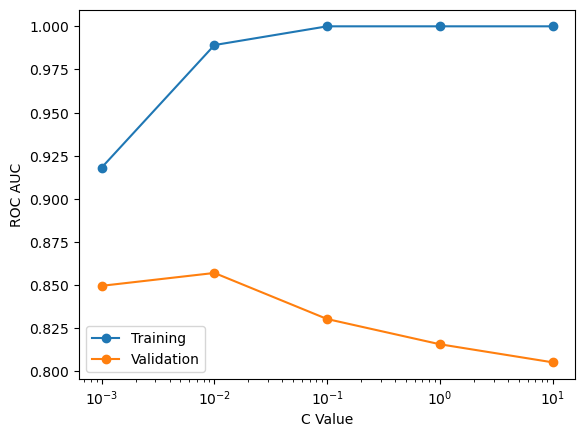

In [40]:
C_values = [0.001, 0.01, 0.1, 1, 10]
train_aucs = []
cv_aucs = []

for C in C_values:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=5000))
    ])

    train_scores = []
    val_scores = []

    for tr, val in sgkf.split(X_train, y_train, groups_train):
        model.fit(X_train.iloc[tr], y_train.iloc[tr])

        train_prob = model.predict_proba(X_train.iloc[tr])[:, 1]
        val_prob = model.predict_proba(X_train.iloc[val])[:, 1]

        train_scores.append(roc_auc_score(y_train.iloc[tr], train_prob))
        val_scores.append(roc_auc_score(y_train.iloc[val], val_prob))

    train_aucs.append(np.mean(train_scores))
    cv_aucs.append(np.mean(val_scores))

results = pd.DataFrame({
    "C": C_values,
    "Train AUC": train_aucs,
    "CV AUC": cv_aucs
})

display(results.round(3))

plt.semilogx(C_values, train_aucs, "o-", label="Training")
plt.semilogx(C_values, cv_aucs, "o-", label="Validation")
plt.xlabel("C Value")
plt.ylabel("ROC AUC")
plt.legend()
plt.show()


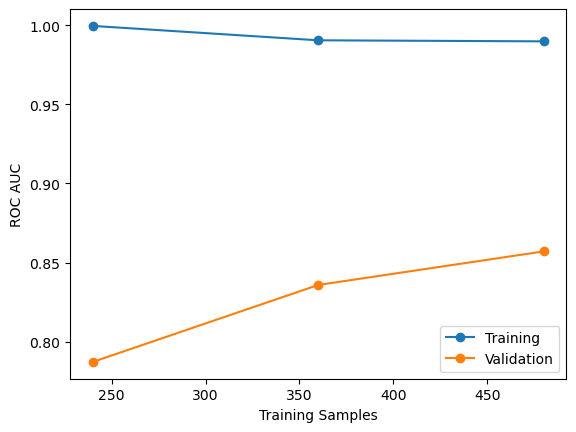

In [41]:
from sklearn.model_selection import learning_curve

best_C = results.loc[results["CV AUC"].idxmax(), "C"]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=best_C, max_iter=5000))
])

sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc",
    train_sizes=[0.5, 0.75, 1.0]
)

plt.plot(sizes, train_scores.mean(axis=1), "o-", label="Training")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="Validation")
plt.xlabel("Training Samples")
plt.ylabel("ROC AUC")
plt.legend()
plt.show()


In [42]:
for penalty in ["l1", "l2", "elasticnet"]:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty=penalty,
            solver="saga",
            C=best_C,
            l1_ratio=0.5 if penalty == "elasticnet" else None,
            max_iter=10000,
            random_state=42
        ))
    ])

    scores = get_auc_cv(
        model, X_train, y_train, sgkf, groups_train
    )

    model.fit(X_train, y_train)

    coefficients = model.named_steps["model"].coef_
    nonzero = np.sum(np.abs(coefficients) > 0.000001)

    print(penalty)
    print("Mean AUC:", round(scores.mean(), 3))
    print("SD:", round(scores.std(ddof=1), 3))
    print("Nonzero coefficients:", nonzero)
    print()


l1
Mean AUC: 0.532
SD: 0.073
Nonzero coefficients: 2

l2
Mean AUC: 0.857
SD: 0.076
Nonzero coefficients: 753

elasticnet
Mean AUC: 0.822
SD: 0.052
Nonzero coefficients: 22



In [43]:

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=best_C, max_iter=5000))
])

model.fit(X_train, y_train)

coefficients = pd.Series(
    model.named_steps["model"].coef_[0],
    index=X_train.columns
)

top3 = coefficients.abs().nlargest(3).index

odds_results = pd.DataFrame({
    "Feature": top3,
    "Coefficient": coefficients[top3].values,
    "Odds Ratio": np.exp(coefficients[top3].values)
})

display(odds_results.round(3))

,Feature,Coefficient,Odds Ratio
0,tqwt_meanValue_dec_36,-0.153,0.859
1,mean_2nd_delta,-0.129,0.879
2,tqwt_medianValue_dec_36,-0.127,0.881


Q:4

My results show that the model starts to overfit as C increases. At C = 1, the training AUC was 1.000, while the validation AUC was 0.816, giving a gap of 0.184. The best validation AUC was 0.857 at C = 0.01, which suggests that stronger regularization helps the model perform better. The learning curve also shows that validation AUC increased from about 0.788 to 0.858 as more training data was added, so having more data could help improve the model.

Q9. 

Regularization is important because this dataset has many voice features but only 252 subjects, which makes overfitting more likely. In my results, L2 performed the best with an AUC of 0.857, compared to 0.822 for Elastic Net and 0.532 for L1. L1 only kept 2 features, while L2 kept 753, showing that L1 may have removed too much information. My top feature was tqwt_meanValue_dec_36, with an odds ratio of 0.859, meaning a one-standard-deviation increase in this feature was associated with about 14.1% lower estimated odds of Parkinson's disease, holding the other features constant. However, this does not mean the feature causes or prevents Parkinson's disease.

In [47]:
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold
)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.svm import SVC
import time

inner_cv = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=42
)

outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100, random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

parameters = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },
    "Random Forest": {
        "model__max_depth": [5, 10, None],
        "model__min_samples_leaf": [1, 3]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}


In [51]:
search_results = []
search_objects = {}

for name in models:

    searches = {
        "Grid": GridSearchCV(
            models[name], parameters[name],
            cv=inner_cv, scoring="roc_auc"
        ),

        "Random": RandomizedSearchCV(
            models[name], parameters[name],
            n_iter=4, cv=inner_cv,
            scoring="roc_auc", random_state=42
        ),

        "Halving": HalvingRandomSearchCV(
            models[name], parameters[name],
            n_candidates=4,
            cv=inner_cv,
            scoring="roc_auc",
            min_resources=300,
            random_state=42
        )
    }

    for method, search in searches.items():
        start = time.time()

        search.fit(X_train, y_train, groups=groups_train)

        runtime = time.time() - start

        search_objects[(name, method)] = search

        search_results.append([
            name,
            method,
            search.best_score_,
            runtime,
            search.best_params_
        ])

search_df = pd.DataFrame(
    search_results,
    columns=["Model", "Search", "AUC", "Seconds", "Best Parameters"]
)

display(search_df.round(3))



,Model,Search,AUC,Seconds,Best Parameters
0,Logistic Regression,Grid,0.860,1.241,{'model__C': 0.01}
1,Logistic Regression,Random,0.860,1.304,{'model__C': 0.01}
2,Logistic Regression,Halving,0.810,1.004,{'model__C': 0.01}
3,Random Forest,Grid,0.869,10.024,"{'model__max_depth': None, 'model__min_samples..."
4,Random Forest,Random,0.869,6.575,"{'model__min_samples_leaf': 3, 'model__max_dep..."
5,Random Forest,Halving,0.840,4.065,"{'model__min_samples_leaf': 1, 'model__max_dep..."
6,SVM,Grid,0.861,2.791,"{'model__C': 10, 'model__kernel': 'rbf'}"
7,SVM,Random,0.861,2.081,"{'model__kernel': 'rbf', 'model__C': 10}"
8,SVM,Halving,0.813,1.128,"{'model__kernel': 'rbf', 'model__C': 0.1}"


In [49]:
nested_results = []

for name in models:
    auc_scores = []

    for tr, val in outer_cv.split(
        X_train, y_train, groups_train
    ):
        search = RandomizedSearchCV(
            models[name],
            parameters[name],
            n_iter=4,
            cv=inner_cv,
            scoring="roc_auc",
            random_state=42
        )

        search.fit(
            X_train.iloc[tr],
            y_train.iloc[tr],
            groups=groups_train[tr]
        )

        predictions = search.predict_proba(
            X_train.iloc[val]
        )[:, 1]

        auc = roc_auc_score(y_train.iloc[val], predictions)
        auc_scores.append(auc)

    nested_results.append([
        name,
        np.mean(auc_scores),
        np.std(auc_scores, ddof=1),
        np.round(auc_scores, 3).tolist()
    ])

nested_df = pd.DataFrame(
    nested_results,
    columns=["Model", "Outer AUC mean", "Outer AUC SD", "Outer fold AUCs"]
)

display(nested_df.round(3))


,Model,Outer AUC mean,Outer AUC SD,Outer fold AUCs
0,Logistic Regression,0.860,0.060,"[0.811, 0.927, 0.842]"
1,Random Forest,0.868,0.048,"[0.84, 0.924, 0.84]"
2,SVM,0.810,0.051,"[0.767, 0.866, 0.796]"


In [50]:

for i, (train_idx, val_idx) in enumerate(
    sgkf.split(X_train, y_train, groups_train)
):
    print("Fold", i + 1)
    print(y_train.iloc[val_idx].value_counts())

Fold 1
class
1    90
0    33
Name: count, dtype: int64
Fold 2
class
1    96
0    24
Name: count, dtype: int64
Fold 3
class
1    90
0    30
Name: count, dtype: int64
Fold 4
class
1    87
0    33
Name: count, dtype: int64
Fold 5
class
1    87
0    33
Name: count, dtype: int64


Q10. 

The Grid Search and Random Search scores were slightly different from the nested CV results. Logistic Regression had a search AUC of 0.860 and a nested AUC of 0.860, while Random Forest went from 0.869 to 0.868. SVM had the biggest difference, going from 0.861 to 0.810. This shows that search scores can sometimes be too optimistic, so I would trust the nested CV results more because they evaluate the models on separate folds.

Q11. 

Random Forest had the highest nested AUC of 0.868 (SD = 0.048), followed by Logistic Regression at 0.860 (SD = 0.060) and SVM at 0.810 (SD = 0.051). Random Forest also had the lowest standard deviation, meaning its performance was slightly more consistent across folds. However, the difference between Random Forest and Logistic Regression was only 0.008, which is small compared to their fold-to-fold variation. I would choose Random Forest for its slightly better performance, but I would want more testing before saying it is definitely the best model.

Q12.

Grid Search and Random Search gave the same AUC for all three models, but Random Search was faster for Random Forest (6.575 seconds vs. 10.024 seconds) and SVM (2.081 seconds vs. 2.791 seconds). Halving Search was generally the fastest, with runtimes of 1.004 seconds for Logistic Regression, 4.065 seconds for Random Forest, and 1.128 seconds for SVM. However, its AUC scores were lower, ranging from 0.810 to 0.840. I would prefer Random Search because it gave similar results to Grid Search while taking less time for the more complex models. Bayesian optimization could also be useful because it uses previous results to guide future parameter choices.

In [52]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve

best_model_name = "Random Forest"

# Use the best Random Forest from Random Search
final_model = clone(
    search_objects[("Random Forest", "Random")].best_estimator_
)

print("Selected model:", best_model_name)
print("Nested CV AUC: 0.868")

Selected model: Random Forest
Nested CV AUC: 0.868


In [53]:
oof_results = {}

for weight in [None, "balanced"]:
    model = clone(final_model)
    model.set_params(model__class_weight=weight)

    predictions = np.zeros(len(y_train))

    for tr, val in sgkf.split(X_train, y_train, groups_train):
        model.fit(X_train.iloc[tr], y_train.iloc[tr])
        predictions[val] = model.predict_proba(X_train.iloc[val])[:, 1]

    oof_results[str(weight)] = predictions

    print("Class weight:", weight)
    print("AUC:", round(roc_auc_score(y_train, predictions), 3))
    print("Average precision:",
          round(average_precision_score(y_train, predictions), 3))
    print()


Class weight: None
AUC: 0.843
Average precision: 0.919

Class weight: balanced
AUC: 0.859
Average precision: 0.936



In [54]:
oof_prob = oof_results["None"]

fpr, tpr, thresholds = roc_curve(y_train, oof_prob)

threshold_table = pd.DataFrame({
    "Threshold": thresholds,
    "Sensitivity": tpr,
    "Specificity": 1 - fpr
})

options = threshold_table[
    threshold_table["Sensitivity"] >= 0.90
]

best_row = options.sort_values(
    ["Specificity", "Threshold"],
    ascending=False
).iloc[0]

chosen_threshold = best_row["Threshold"]

print("Chosen threshold:", round(chosen_threshold, 3))
print("Training sensitivity:", round(best_row["Sensitivity"], 3))
print("Training specificity:", round(best_row["Specificity"], 3))


Chosen threshold: 0.597
Training sensitivity: 0.907
Training specificity: 0.575


In [55]:
final_model.fit(X_train, y_train)

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

test_auc = roc_auc_score(y_test, test_prob)
test_ap = average_precision_score(y_test, test_prob)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Test AUC:", round(test_auc, 3))
print("Average precision:", round(test_ap, 3))
print("Sensitivity:", round(sensitivity, 3))
print("Specificity:", round(specificity, 3))

Test AUC: 0.775
Average precision: 0.916
Sensitivity: 0.877
Specificity: 0.436


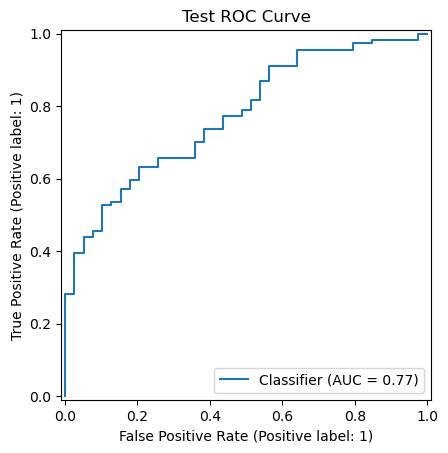

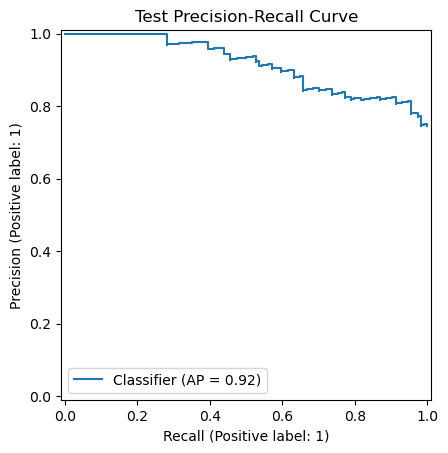

In [56]:
RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("Test ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob)
plt.title("Test Precision-Recall Curve")
plt.show()


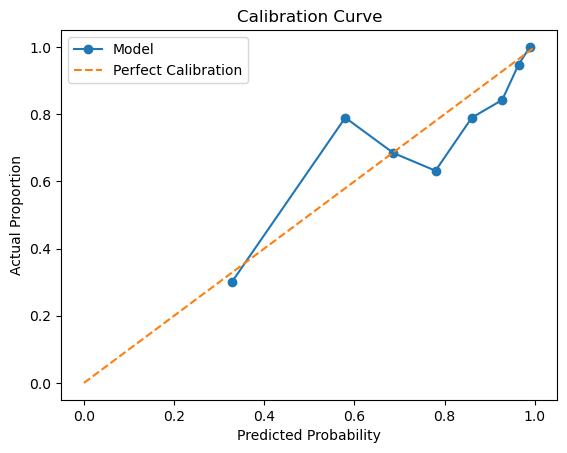

In [57]:
actual, predicted = calibration_curve(
    y_test, test_prob, n_bins=8, strategy="quantile"
)

plt.plot(predicted, actual, "o-", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect Calibration")

plt.xlabel("Predicted Probability")
plt.ylabel("Actual Proportion")
plt.title("Calibration Curve")
plt.legend()
plt.show()

In [59]:
rng = np.random.default_rng(42)

subject_ids = np.asarray(groups_test)
unique_subjects = np.unique(subject_ids)

auc_scores = []

for i in range(1000):
    sampled = rng.choice(
        unique_subjects,
        size=len(unique_subjects),
        replace=True
    )

    indices = np.concatenate([
        np.where(subject_ids == subject)[0]
        for subject in sampled
    ])

    if len(np.unique(y_test.iloc[indices])) < 2:
        continue

    auc = roc_auc_score(
        y_test.iloc[indices],
        test_prob[indices]
    )

    auc_scores.append(auc)

lower, upper = np.percentile(auc_scores, [2.5, 97.5])

print("Test AUC:", round(test_auc, 3))
print("95% Confidence Interval:",
      round(lower, 3), "to", round(upper, 3))


Test AUC: 0.775
95% Confidence Interval: 0.64 to 0.889


Q13.

I chose a threshold of 0.597 using my training data, which gave me a sensitivity of 0.907 and specificity of 0.575 during validation. On the test set, sensitivity was 0.877 and specificity was 0.436, meaning the model identified most Parkinson's recordings but also incorrectly classified many healthy recordings. I also compared class weights and found that balanced weights had a higher AUC of 0.859, compared to 0.843 without weights. For screening, I would prioritize sensitivity because missing someone who may have Parkinson's could be more concerning, but I would still want to reduce false positives.

Q14. 

My final Random Forest model had a test AUC of 0.775, which was lower than the nested cross-validation AUC of 0.868. The average precision was 0.916, showing that the model performed relatively well on the precision-recall measure, although the dataset has more Parkinson's recordings than healthy recordings. The calibration curve showed some differences between predicted probabilities and actual outcomes, so the model's probabilities are not perfectly calibrated. I would want more testing and a larger independent dataset before using this model for actual Parkinson's screening.